In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds


# ---------------- Models ----------------

class MostPopular:
    """Global top-K by purchase frequency in training data."""
    def __init__(self, k=10):
        self.k = k
        self.items_ = None

    def fit(self, df, user_col, item_col, time_col=None):
        counts = Counter(df[item_col])
        self.items_ = [i for i, _ in counts.most_common(self.k)]
        return self

    def recommend(self, users):
        return {u: list(self.items_) for u in users}


class RecentPopular:
    """Top-K by frequency in the most recent `window` fraction of training data."""
    def __init__(self, k=10, window=0.2):
        self.k = k
        self.window = window
        self.items_ = None

    def fit(self, df, user_col, item_col, time_col=None):
        d = df.sort_values(time_col)
        recent = d.tail(max(1, int(len(d) * self.window)))
        counts = Counter(recent[item_col])
        self.items_ = [i for i, _ in counts.most_common(self.k)]
        return self

    def recommend(self, users):
        return {u: list(self.items_) for u in users}


class SVDRecommender:
    """Truncated SVD on the binary user-item matrix."""
    def __init__(self, k=10, latent_dim=50, exclude_seen=True):
        self.k = k
        self.latent_dim = latent_dim
        self.exclude_seen = exclude_seen

    def fit(self, df, user_col, item_col, time_col=None):
        users = df[user_col].astype(str).unique()
        items = df[item_col].astype(str).unique()
        self.user_idx_ = {u: i for i, u in enumerate(users)}
        self.item_idx_ = {it: j for j, it in enumerate(items)}
        self.items_ = list(items)

        rows = df[user_col].astype(str).map(self.user_idx_).values
        cols = df[item_col].astype(str).map(self.item_idx_).values
        data = np.ones(len(df), dtype=np.float32)
        mat = csr_matrix((data, (rows, cols)), shape=(len(users), len(items)))
        self.seen_ = mat

        k = min(self.latent_dim, min(mat.shape) - 1)
        if k < 1:
            self.user_factors_ = np.zeros((len(users), 0), np.float32)
            self.item_factors_ = np.zeros((len(items), 0), np.float32)
            return self
        U, s, Vt = svds(mat, k=k)
        order = np.argsort(-s)
        U, s, Vt = U[:, order], s[order], Vt[order]
        self.user_factors_ = (U * s).astype(np.float32)
        self.item_factors_ = Vt.T.astype(np.float32)
        return self

    def recommend(self, users):
        recs = {}
        pop = np.asarray(self.seen_.sum(axis=0)).ravel()
        pop_top = [self.items_[i] for i in np.argsort(-pop)[: self.k]]

        for u in users:
            u_str = str(u)
            if u_str not in self.user_idx_ or self.item_factors_.shape[1] == 0:
                recs[u] = list(pop_top)
                continue
            ui = self.user_idx_[u_str]
            scores = (self.user_factors_[ui] @ self.item_factors_.T).ravel()
            if self.exclude_seen:
                scores[self.seen_[ui].indices] = -np.inf
            kk = min(self.k, scores.size)
            if kk == 0:
                recs[u] = []; continue
            top = np.argpartition(-scores, kk - 1)[:kk]
            top = top[np.argsort(-scores[top])]
            recs[u] = [self.items_[i] for i in top]
        return recs


class ItemKNN:
    """Item-based CF with cosine similarity, top-N neighbors, popularity fallback."""
    def __init__(self, k=10, n_neighbors=200):
        self.k = k
        self.n_neighbors = n_neighbors

    def fit(self, df, user_col, item_col, time_col=None):
        users = df[user_col].astype(str).unique()
        items = df[item_col].astype(str).unique()
        self.user_idx_ = {u: i for i, u in enumerate(users)}
        self.item_idx_ = {it: j for j, it in enumerate(items)}
        self.items_ = list(items)

        rows = df[user_col].astype(str).map(self.user_idx_).values
        cols = df[item_col].astype(str).map(self.item_idx_).values
        X = csr_matrix((np.ones(len(df), np.float32), (rows, cols)),
                       shape=(len(users), len(items)))
        self.seen_ = X

        norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=0)).ravel()) + 1e-9
        Xn = X.multiply(1.0 / norms).tocsr()
        S = (Xn.T @ Xn).toarray().astype(np.float32)
        np.fill_diagonal(S, 0.0)

        n_nb = min(self.n_neighbors, S.shape[0] - 1)
        if 0 < n_nb < S.shape[0]:
            thresh = -np.partition(-S, n_nb, axis=1)[:, n_nb][:, None]
            S[S < thresh] = 0.0
        self.S_ = S

        self.pop_ = np.asarray(X.sum(axis=0)).ravel()
        return self

    def recommend(self, users):
        pop_top = [self.items_[i] for i in np.argsort(-self.pop_)[: self.k]]
        recs = {}
        for u in users:
            ui = self.user_idx_.get(str(u))
            if ui is None:
                recs[u] = list(pop_top); continue
            scores = np.asarray((self.seen_[ui] @ self.S_)).ravel()
            kk = min(self.k, scores.size)
            if kk == 0:
                recs[u] = []; continue
            top = np.argpartition(-scores, kk - 1)[:kk]
            top = top[np.argsort(-scores[top])]
            recs[u] = [self.items_[i] for i in top]
        return recs


class EASE:
    """Embarrassingly Shallow AutoEncoder (Steck 2019) — closed form."""
    def __init__(self, k=10, l2=200.0):
        self.k = k
        self.l2 = l2

    def fit(self, df, user_col, item_col, time_col=None):
        users = df[user_col].astype(str).unique()
        items = df[item_col].astype(str).unique()
        self.user_idx_ = {u: i for i, u in enumerate(users)}
        self.item_idx_ = {it: j for j, it in enumerate(items)}
        self.items_ = list(items)

        rows = df[user_col].astype(str).map(self.user_idx_).values
        cols = df[item_col].astype(str).map(self.item_idx_).values
        X = csr_matrix((np.ones(len(df), np.float32), (rows, cols)),
                       shape=(len(users), len(items)))
        self.seen_ = X

        G = (X.T @ X).toarray().astype(np.float64)
        diag = np.diag_indices(G.shape[0])
        G[diag] += self.l2
        P = np.linalg.inv(G)
        B = -P / np.diag(P)[None, :]
        np.fill_diagonal(B, 0.0)
        self.B_ = B.astype(np.float32)
        return self

    def recommend(self, users):
        Xt = self.seen_.T.tocsr()
        recs = {}
        for u in users:
            ui = self.user_idx_.get(str(u))
            if ui is None:
                recs[u] = []; continue
            scores = np.asarray(Xt[:, ui].T @ self.B_).ravel()
            kk = min(self.k, scores.size)
            if kk == 0:
                recs[u] = []; continue
            top = np.argpartition(-scores, kk - 1)[:kk]
            top = top[np.argsort(-scores[top])]
            recs[u] = [self.items_[i] for i in top]
        return recs

class EmbeddingAvg:
    def __init__(self, k=10, dim=64, min_count=1):
        self.k = k
        self.dim = dim
        self.min_count = min_count

    def fit(self, df, user_col, item_col, time_col=None):
        users = df[user_col].astype(str).unique()
        items = df[item_col].astype(str).unique()
        self.user_idx_ = {u: i for i, u in enumerate(users)}
        self.item_idx_ = {it: j for j, it in enumerate(items)}
        self.items_ = list(items)
        n_users, n_items = len(users), len(items)

        rows = df[user_col].astype(str).map(self.user_idx_).values
        cols = df[item_col].astype(str).map(self.item_idx_).values
        X = csr_matrix((np.ones(len(df), np.float32), (rows, cols)),
                       shape=(n_users, n_items))
        X.data = np.ones_like(X.data)          # binarize
        self.seen_ = X
        self.pop_ = np.asarray(X.sum(axis=0)).ravel()

        # sparse co-occurrence — never densified
        C = (X.T @ X).tocsr().astype(np.float64)
        C.setdiag(0.0)
        C.eliminate_zeros()

        # PPMI on the non-zero entries only
        C = C.tocoo()
        row_sum = np.asarray(C.sum(axis=1)).ravel()
        col_sum = np.asarray(C.sum(axis=0)).ravel()
        total   = C.data.sum() + 1e-9
        with np.errstate(divide="ignore", invalid="ignore"):
            pmi = np.log(C.data * total /
                         (row_sum[C.row] * col_sum[C.col] + 1e-9))
        pmi = np.nan_to_num(pmi, nan=0.0, posinf=0.0, neginf=0.0)
        mask = pmi > 0
        P = csr_matrix((pmi[mask], (C.row[mask], C.col[mask])), shape=C.shape)

        # truncated SVD on sparse PPMI
        d = min(self.dim, min(P.shape) - 1)
        if d < 1 or P.nnz == 0:
            E = np.zeros((n_items, 1), np.float32)
        else:
            U, s, Vt = svds(P, k=d)          # scipy accepts sparse
            order = np.argsort(-s)
            E = (Vt[order].T * np.sqrt(np.maximum(s[order], 0.0))[None, :]
                 ).astype(np.float32)
        self.item_emb_  = E
        self.item_emb_n_ = (E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
                            ).astype(np.float32)
        return self

    def recommend(self, users):
        pop_top = [self.items_[i] for i in np.argsort(-self.pop_)[: self.k]]
        recs = {}
        for u in users:
            ui = self.user_idx_.get(str(u))
            if ui is None:
                recs[u] = list(pop_top); continue
            idxs = self.seen_[ui].indices
            if idxs.size == 0:
                recs[u] = list(pop_top); continue

            uprof = self.item_emb_n_[idxs].mean(axis=0)
            uprof = uprof / (np.linalg.norm(uprof) + 1e-9)

            scores = self.item_emb_n_ @ uprof
            scores[idxs] = -np.inf

            kk = min(self.k, scores.size)
            top = np.argpartition(-scores, kk - 1)[:kk]
            top = top[np.argsort(-scores[top])]
            recs[u] = [self.items_[i] for i in top if np.isfinite(scores[i])]
        return recs

        
# ---------------- Metrics ----------------

def precision_at_k(recs, truth, k):
    return np.mean([len(set(recs[u][:k]) & truth[u]) / k for u in truth])

def recall_at_k(recs, truth, k):
    return np.mean([len(set(recs[u][:k]) & truth[u]) / len(truth[u]) for u in truth])

def hit_rate_at_k(recs, truth, k):
    return np.mean([1.0 if set(recs[u][:k]) & truth[u] else 0.0 for u in truth])

def ndcg_at_k(recs, truth, k):
    vals = []
    for u, t in truth.items():
        t = set(t); dcg = 0.0
        for i, it in enumerate(recs[u][:k], 1):
            if it in t:
                dcg += 1 / np.log2(i + 1)
        ideal = sum(1 / np.log2(i + 1) for i in range(1, min(len(t), k) + 1))
        vals.append(dcg / ideal if ideal else 0.0)
    return np.mean(vals)


# ---------------- Comparator ----------------

class ModelComparator:
    """
    split: 'global_time' (default) | 'random' | 'per_user_time'
    """
    def __init__(self, models, k=10, split="global_time",
                 val_size=0.15, test_size=0.15, random_state=42):
        self.models = models
        self.k = k
        self.split = split
        self.val_size = val_size
        self.test_size = test_size
        self.random_state = random_state
        self.results_ = None

    def _split(self, df, user_col, time_col):
        vs, ts = self.val_size, self.test_size
        if self.split == "global_time":
            d = df.sort_values(time_col).reset_index(drop=True)
            n = len(d); n_te = int(n * ts); n_va = int(n * vs)
            return (d.iloc[:n - n_te - n_va],
                    d.iloc[n - n_te - n_va:n - n_te],
                    d.iloc[n - n_te:])
        if self.split == "random":
            d = df.sample(frac=1.0, random_state=self.random_state).reset_index(drop=True)
            n = len(d); n_te = int(n * ts); n_va = int(n * vs)
            return (d.iloc[:n - n_te - n_va],
                    d.iloc[n - n_te - n_va:n - n_te],
                    d.iloc[n - n_te:])
        if self.split == "per_user_time":
            parts = {"train": [], "val": [], "test": []}
            for _, g in df.sort_values(time_col).groupby(user_col):
                n = len(g); n_te = max(1, int(n * ts)); n_va = max(1, int(n * vs))
                if n - n_te - n_va < 1:
                    parts["train"].append(g); continue
                parts["train"].append(g.iloc[:n - n_te - n_va])
                parts["val"].append(g.iloc[n - n_te - n_va:n - n_te])
                parts["test"].append(g.iloc[n - n_te:])
            return tuple(pd.concat(parts[s]) if parts[s] else df.iloc[0:0]
                         for s in ("train", "val", "test"))
        raise ValueError(f"Unknown split: {self.split}")

    def run(self, df, user_col="Survey ResponseID",
            item_col="ASIN/ISBN (Product Code)", time_col="Order Date"):
        train, val, test = self._split(df, user_col, time_col)
        truth = test.groupby(user_col)[item_col].apply(set).to_dict()
        if not truth:
            raise RuntimeError("Empty test set after split.")

        results = {}
        for name, model in self.models.items():
            model.fit(train, user_col, item_col, time_col)
            recs = model.recommend(truth.keys())
            k = self.k
            results[name] = {
                f"Precision@{k}": precision_at_k(recs, truth, k),
                f"Recall@{k}":    recall_at_k(recs, truth, k),
                f"HitRate@{k}":   hit_rate_at_k(recs, truth, k),
                f"NDCG@{k}":      ndcg_at_k(recs, truth, k),
            }
        self.results_ = pd.DataFrame(results).T
        return self.results_

    def plot(self, figsize=(12, 8)):
        if self.results_ is None:
            raise RuntimeError("Call run() first.")

        metrics = list(self.results_.columns)
        n = len(metrics)
        ncols = 2
        nrows = int(np.ceil(n / ncols))

        palette = plt.cm.tab10(np.linspace(0, 1, len(self.results_.index)))
        color_map = dict(zip(self.results_.index, palette))

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
        axes = np.array(axes).reshape(-1)

        for ax, metric in zip(axes, metrics):
            values = self.results_[metric]
            colors = [color_map[m] for m in values.index]
            bars = ax.bar(values.index, values.values, color=colors,
                          edgecolor="black", linewidth=0.6)

            for bar, v in zip(bars, values.values):
                ax.text(bar.get_x() + bar.get_width() / 2,
                        bar.get_height() + 0.005,
                        f"{v:.3f}", ha="center", va="bottom", fontsize=9)

            ax.set_title(metric, fontsize=12, fontweight="bold")
            ax.set_ylabel("score")
            ymax = max(0.05, values.max() * 1.2)
            ax.set_ylim(0, ymax)
            ax.grid(axis="y", linestyle="--", alpha=0.4)
            ax.set_axisbelow(True)
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
            ax.tick_params(axis="x", rotation=0)

        for ax in axes[len(metrics):]:
            ax.axis("off")

        fig.suptitle("Model Comparison", fontsize=14, fontweight="bold")
        fig.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()


In [2]:
df = pd.read_csv("../data/Amazon1.0/amazon-purchases.csv")
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")


                Precision@10  Recall@10  HitRate@10   NDCG@10
ItemKNN             0.223658   0.074481    0.755420  0.239423
EASE                0.310145   0.113306    0.825721  0.342783
MostPopular         0.276679   0.107274    0.846769  0.297165
RecentPopular       0.244159   0.094552    0.827615  0.293572
SVD                 0.101389   0.037726    0.550410  0.110650
ItemEmbeddings      0.106525   0.042291    0.577563  0.114868


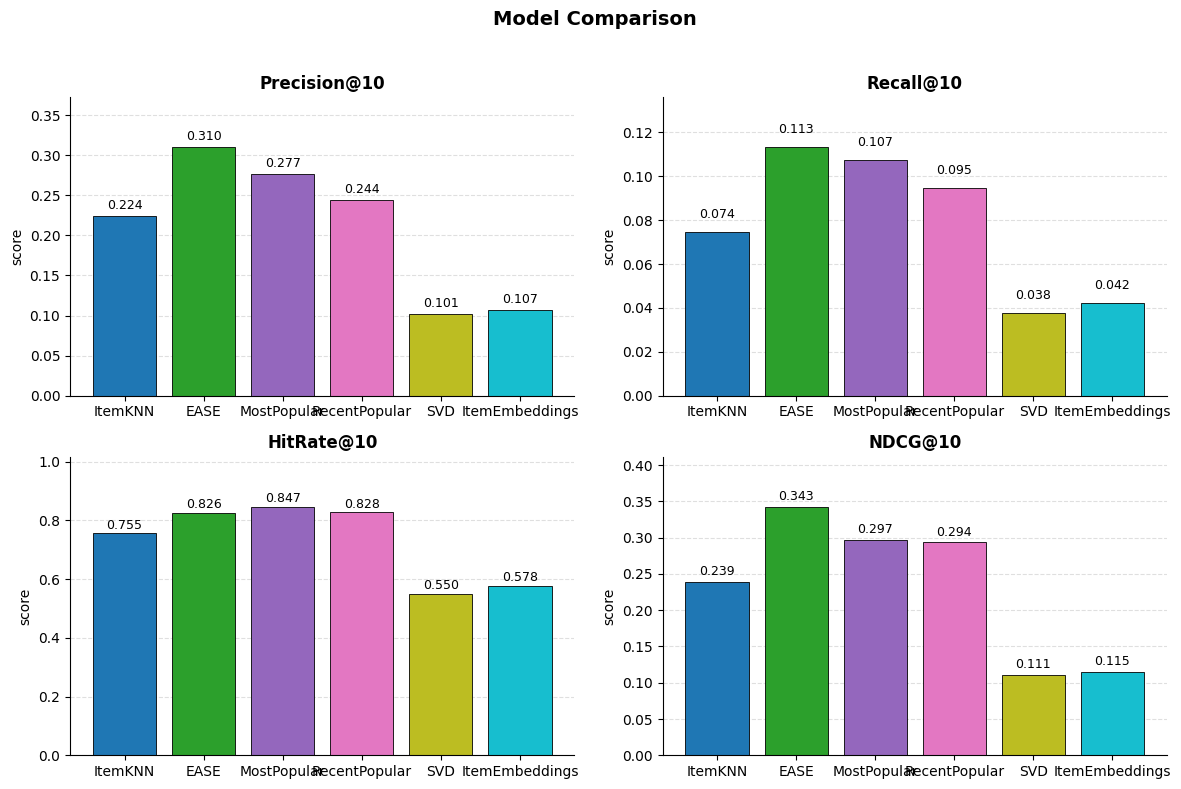

In [3]:
cmp = ModelComparator(
    models={
        "ItemKNN":       ItemKNN(k=10, n_neighbors=200),
        "EASE":          EASE(k=10, l2=200.0),
        "MostPopular":   MostPopular(k=10),
        "RecentPopular": RecentPopular(k=10, window=0.2),
        "SVD":           SVDRecommender(k=10, latent_dim=50),
        "ItemEmbeddings" : EmbeddingAvg()
    },
    k=10,
    split="global_time",
)
res = cmp.run(df, item_col="Category")
print(res)
cmp.plot()

               Precision@10  Recall@10  HitRate@10   NDCG@10
MostPopular        0.018207   0.008115    0.157441  0.022818
RecentPopular      0.019217   0.008115    0.163755  0.023143
SVD                0.003284   0.001188    0.029888  0.003964


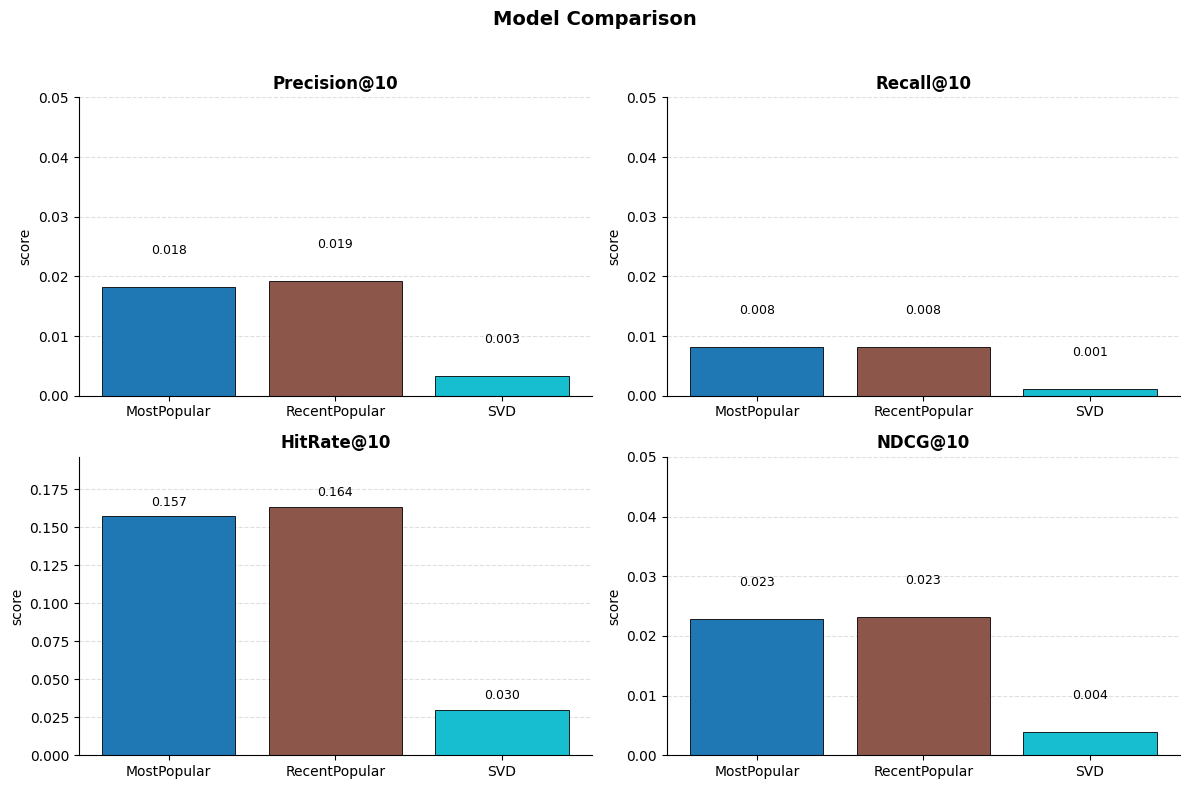

In [ ]:
cmp = ModelComparator(
    models={
        # "ItemKNN":       ItemKNN(k=10, n_neighbors=200),
        # "EASE":          EASE(k=10, l2=200.0),
        "MostPopular":   MostPopular(k=10),
        "RecentPopular": RecentPopular(k=10, window=0.2),
        "SVD":           SVDRecommender(k=10, latent_dim=50),
        "ItemEmbeddings" : EmbeddingAvg()
    },
    k=10,
    split="global_time",
)
res = cmp.run(df)
print(res)
cmp.plot()